In [ ]:
!pip install ultralytics opencv-python

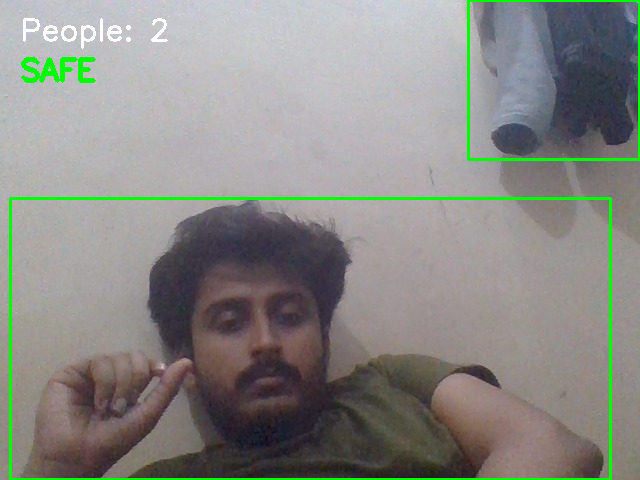

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display, Javascript, clear_output
from google.colab.output import eval_js
import cv2
import numpy as np
import base64
from ultralytics import YOLO

# Load model
model = YOLO("yolov8n.pt")

SAFE_LIMIT = 3

def take_photo():
    js = Javascript('''
    async function takePhoto() {
      const video = document.createElement('video');
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(video);
      video.srcObject = stream;
      await video.play();

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getTracks().forEach(track => track.stop());
      video.remove();

      return canvas.toDataURL('image/jpeg');
    }
    takePhoto();
    ''')

    display(js)
    data = eval_js("takePhoto()")

    binary = base64.b64decode(data.split(',')[1])
    img = np.frombuffer(binary, dtype=np.uint8)
    return cv2.imdecode(img, cv2.IMREAD_COLOR)

# 🔁 LOOP (simulate live)
while True:
    frame = take_photo()

    results = model(frame)

    person_count = 0

    for r in results:
        for box in r.boxes:
            if int(box.cls[0]) == 0:
                person_count += 1
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)

    status = "SAFE" if person_count <= SAFE_LIMIT else "⚠ ABOVE SAFE LIMIT"

    cv2.putText(frame, f"People: {person_count}", (20,40),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)

    cv2.putText(frame, status, (20,80),
                cv2.FONT_HERSHEY_SIMPLEX, 1,
                (0,255,0) if status=="SAFE" else (0,0,255), 3)

    clear_output(wait=True)
    from google.colab.patches import cv2_imshow
    cv2_imshow(frame)